# Cat Breed Classification with a Small Vision Transformer

A small pretrained Vision Transformer (DeiT-Tiny, 5.5 M parameters) is fine-tuned to recognise 12 cat breeds.

The whole idea in one line: the model has already learned to "see" from about 1.28 million everyday photos, and fine-tuning trains it a bit more on labelled cat photos so that it gets good at telling these 12 breeds apart.

**Pipeline:** 1. Data selection → 2. Pre-processing → 3. Fine-tuning → 4. Testing and F1 → 5. Summary

| Stage | Goes in | What happens | Comes out |
|---|---|---|---|
| 1. Data selection | Oxford-IIIT Pet: 37 breeds, 7,349 labelled photos | Keep the 12 cat breeds and the official split | 1,188 training and 1,183 test photos |
| 2. Pre-processing | Raw photos of any size, RGB or RGBA | RGB → resize to 224 × 224 → random flip (training only) → normalise | Tensors of 3 × 224 × 224 numbers |
| 3. Fine-tuning | Pre-trained DeiT-Tiny + training tensors | New 12-class head; 190 AdamW steps on all 5.5 M parameters | Fine-tuned model |
| 4. Testing and F1 | Fine-tuned model + unseen test photos | Predict, compare with the true labels, score each breed | Macro F1 before vs after training |

Runs on Google Colab (GPU), Apple Silicon or CPU.

## Setup

In [1]:
%pip install -q torch torchvision transformers datasets scikit-learn matplotlib pandas

Note: you may need to restart the kernel to use updated packages.


In [2]:
import random
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms

import datasets
import transformers
from datasets import load_dataset
from transformers import AutoImageProcessor, AutoModelForImageClassification
from sklearn.metrics import accuracy_score, f1_score

transformers.logging.set_verbosity_error()
transformers.logging.disable_progress_bar()
datasets.disable_progress_bars()

SEED = 42             # fixes all random choices, so every run gives the same numbers
MODEL_ID = "facebook/deit-tiny-patch16-224"
EPOCHS = 5            # training loss is close to zero after 5 passes over the data
BATCH_SIZE = 32       # images per update; fits easily in GPU memory
LEARNING_RATE = 1e-4  # small steps keep what the model learned in pre-training

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    device = "cuda"
elif torch.backends.mps.is_available():
    device = "mps"
else:
    device = "cpu"
print("Device:", device)

FIG_DIR, RESULTS_DIR = Path("figures"), Path("results")
FIG_DIR.mkdir(exist_ok=True)
RESULTS_DIR.mkdir(exist_ok=True)

Device: mps


## 1. Data selection

**Oxford-IIIT Pet dataset** (Parkhi et al., 2012), loaded from the Hugging Face Hub as [`timm/oxford-iiit-pet`](https://huggingface.co/datasets/timm/oxford-iiit-pet). The Hugging Face Hub is an online library of public datasets and models; one line of code downloads them. The dataset has 7,349 web photos of 37 cat and dog breeds. Each photo comes with a **label**, the correct breed written down by the dataset authors, and these labels are what the model learns from. Licence: CC BY-SA 4.0, free to reuse with credit.

The dataset also has an official **train/test split**. The model learns only from the train photos; the test photos are kept aside for the final check, like an exam with questions it has never seen.

Why this dataset:

- **Labelled and public.** Every photo already has its breed, and the licence allows reuse, so anyone can rerun this notebook.
- **Fine-grained.** Several breeds look alike, e.g. British Shorthair and Russian Blue are both grey, so the model has to pick up small details rather than just "this is a cat".
- **Balanced.** About 100 photos per breed in each split, so no single breed dominates the score.
- **Small.** 2,371 cat photos: fine-tuning takes minutes, and it is a realistic small-data case for a pre-trained model.

| Step | Operation | Reason |
|---|---|---|
| 1 | Keep only the 12 cat breeds (`label_cat_dog == 0`) | The task is cat breeds, so the dog photos are dropped |
| 2 | Renumber the breeds 0–11 | The model outputs a breed number, not a name, so the 12 breeds need the numbers 0 to 11 |
| 3 | Keep the official train/test split | Test photos are never seen during training, so the final score is honest |

In [3]:
pets = load_dataset("timm/oxford-iiit-pet")
all_breeds = pets["train"].features["label"].names

# Step 1: keep cats only
cats = pets.filter(lambda is_dog: is_dog == 0, input_columns="label_cat_dog")

# Step 2: renumber the 12 breeds as 0..11
cat_ids = sorted(set(cats["train"]["label"]))
class_names = [all_breeds[i].replace("_", " ").title() for i in cat_ids]
new_id = {old: new for new, old in enumerate(cat_ids)}
cats = cats.map(lambda label: {"y": new_id[label]}, input_columns="label")

# Step 3: official split
train_data, test_data = cats["train"], cats["test"]

counts = pd.DataFrame({
    "train": pd.Series(train_data["y"]).value_counts().sort_index().values,
    "test": pd.Series(test_data["y"]).value_counts().sort_index().values,
}, index=class_names)
counts.loc["Total"] = counts.sum()
counts

,train,test
Abyssinian,100,98
Bengal,100,100
Birman,100,100
Bombay,96,88
British Shorthair,100,100
Egyptian Mau,93,97
Maine Coon,100,100
Persian,100,100
Ragdoll,100,100
Russian Blue,100,100


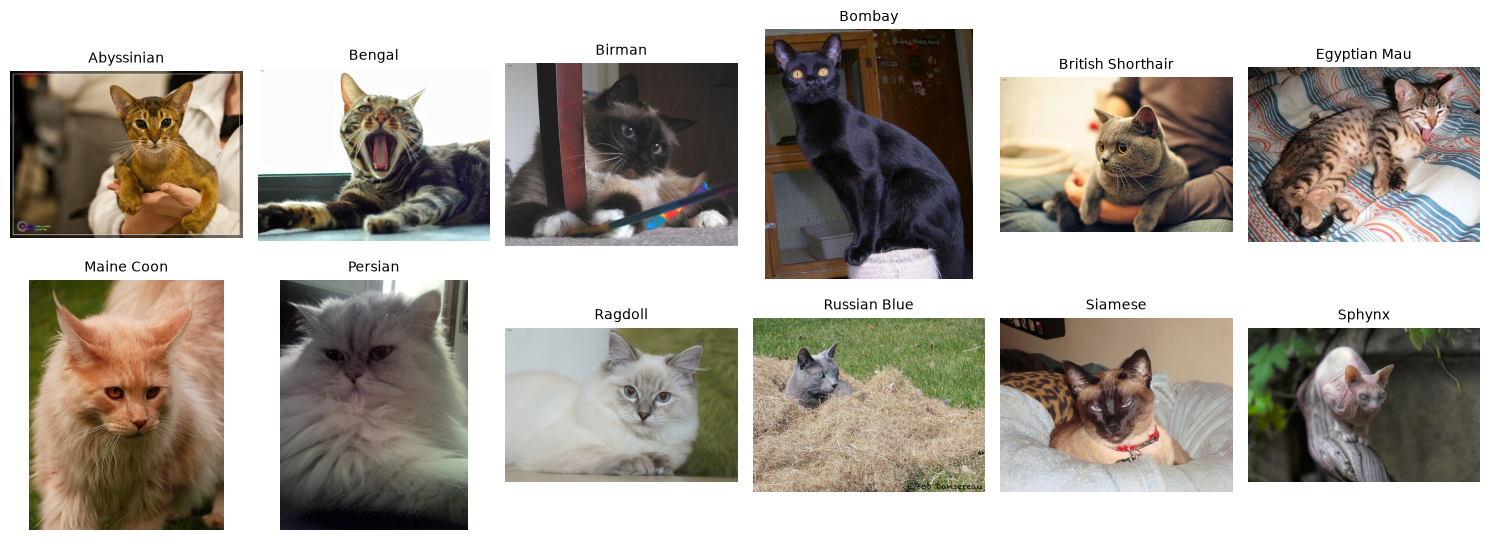

In [4]:
fig, axes = plt.subplots(2, 6, figsize=(15, 5.5))
labels = list(train_data["y"])
for c, ax in enumerate(axes.flat):
    ax.imshow(train_data[labels.index(c)]["image"])
    ax.set_title(class_names[c], fontsize=10)
    ax.axis("off")
fig.tight_layout()
fig.savefig(FIG_DIR / "dataset_samples.png", dpi=120, bbox_inches="tight")
plt.show()

## 2. Pre-processing

**Pre-processing** means getting every raw photo into the same size and number format before the model sees it. The raw photos are far from uniform, as the check below shows.

In [5]:
for name, split in [("train", train_data), ("test", test_data)]:
    images = split["image"]
    widths = [img.size[0] for img in images]
    heights = [img.size[1] for img in images]
    print(f"{name}: modes {dict(Counter(img.mode for img in images))}, "
          f"width {min(widths)}-{max(widths)} px, height {min(heights)}-{max(heights)} px")

train: modes {'RGB': 1186, 'RGBA': 2}, width 114-3264 px, height 108-2606 px


test: modes {'RGB': 1182, 'RGBA': 1}, width 137-1646 px, height 103-2160 px


| Step | Operation | Reason |
|---|---|---|
| 4 | Convert every image to RGB | RGB = the red, green and blue colour channels. 3 photos are RGBA, which adds a 4th channel for transparency; the model only accepts 3 |
| 5 | Resize to 224 × 224 | The model was built for 224 × 224 inputs; original widths range from 114 to 3,264 pixels |
| 6 | Random horizontal flip (training only) | **Data augmentation**: a mirrored cat is still the same breed, so flipping adds variety without new photos |
| 7 | Convert to a tensor and normalise (mean 0.5, std 0.5 per channel) | A **tensor** is the grid of pixel numbers the model reads. Normalising moves the values from 0–1 to −1–1, the range the model saw in pre-training |

`transforms.Compose` chains steps 5–7 so they run one after another on every photo; step 4 runs when each photo is loaded. A **DataLoader** then hands the photos to the model in batches of 32.

In [6]:
processor = AutoImageProcessor.from_pretrained(MODEL_ID)
normalize = transforms.Normalize(processor.image_mean, processor.image_std)  # 0.5, 0.5

train_tf = transforms.Compose([
    transforms.Resize((224, 224)),      # step 5
    transforms.RandomHorizontalFlip(),  # step 6 (training only)
    transforms.ToTensor(),              # step 7
    normalize,
])
test_tf = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    normalize,
])


class CatDataset(Dataset):
    def __init__(self, data, transform):
        self.data, self.transform = data, transform

    def __len__(self):
        return len(self.data)

    def __getitem__(self, i):
        example = self.data[i]
        image = example["image"].convert("RGB")  # step 4
        return self.transform(image), example["y"]


train_loader = DataLoader(CatDataset(train_data, train_tf), batch_size=BATCH_SIZE,
                          shuffle=True)
test_loader = DataLoader(CatDataset(test_data, test_tf), batch_size=BATCH_SIZE)

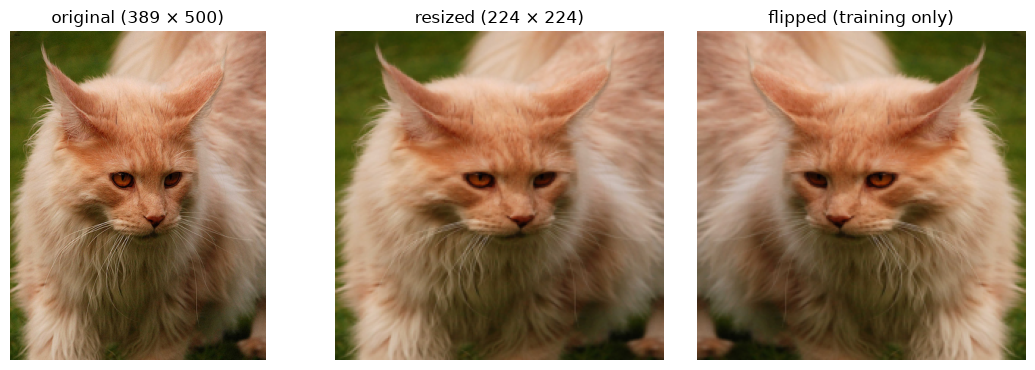

In [7]:
image = train_data[0]["image"].convert("RGB")
resized = transforms.functional.resize(image, (224, 224))
flipped = transforms.functional.hflip(resized)

titles = [
    f"original ({image.size[0]} × {image.size[1]})",
    "resized (224 × 224)",
    "flipped (training only)",
]
fig, axes = plt.subplots(1, 3, figsize=(11, 3.8))
for ax, img, title in zip(axes, [image, resized, flipped], titles):
    ax.imshow(img)
    ax.set_title(title)
    ax.axis("off")
fig.tight_layout()
fig.savefig(FIG_DIR / "preprocessing.png", dpi=120, bbox_inches="tight")
plt.show()

What comes out of this stage, checked on one test photo: 3 colour channels × 224 × 224 pixels, with values between −1 and 1.

In [8]:
x, _ = test_loader.dataset[0]
print("model input:", tuple(x.shape), f"values {x.min():.2f} to {x.max():.2f}")

model input: (3, 224, 224) values -1.00 to 0.93


## 3. Fine-tuning

### 3.1 Model choice: why DeiT-Tiny

[`facebook/deit-tiny-patch16-224`](https://huggingface.co/facebook/deit-tiny-patch16-224) (Touvron et al., 2021). DeiT stands for *Data-efficient image Transformer*. A **Vision Transformer (ViT)** cuts a photo into small squares and lets every square compare itself with every other square to work out which parts belong together, for example the ears with the face.

- **Few parameters.** 5.5 M, about 1/15 of ViT-Base (86 M). Parameters are the adjustable numbers inside the model, and training is nothing more than changing them. Fewer numbers, so it fine-tunes in minutes on a single laptop GPU.
- **A standard Vision Transformer.** Same design as the original ViT (Dosovitskiy et al., 2021): the photo becomes 16 × 16 **patches** that are processed by **self-attention** layers. Self-attention is the "every square compares itself with every other square" step.
- **Data-efficient pre-training.** **Pre-training** is the earlier, much bigger training run done by the model's authors; it is where the model learned edges, fur, eyes and shapes. DeiT was pre-trained on **ImageNet-1k** alone (about 1.28 million photos of 1,000 everyday categories), without the very large extra datasets used for the original ViT.
- **Relevant pre-training.** ImageNet-1k contains cat classes such as Persian cat, Siamese cat and Egyptian cat, so features useful for cat photos are already there before fine-tuning.
- **Ready to use.** The official **checkpoint**, the saved file of all trained parameter values, is on the Hugging Face Hub.

**Why 192 numbers per token.** Each patch is described by 192 numbers, called a **token**. The number comes with the pre-trained model; it is not tuned in this project. DeiT keeps every **attention head** (one self-attention comparison) 64 numbers wide and only changes how many heads there are: Tiny has 3 × 64 = 192, Small 6 × 64 = 384, and Base 12 × 64 = 768, the same as ViT-Base. So Tiny is a quarter of the width of Base. Most of the weights are width × width tables, so a quarter of the width gives roughly (1/4)² = 1/16 of the parameters, which matches the "about 1/15 of ViT-Base" above. Changing 192 would mean training the whole model again from scratch and losing the pre-training.

### 3.2 Architecture

```
photo, 3 × 224 × 224 numbers (from Step 2)
  │  cut into 196 patches of 16 × 16 pixels
  ▼
patch + position embeddings      each patch → 192 numbers, plus where it sits,
                                 plus one extra [CLS] summary token → 197 tokens × 192
  ▼
Transformer encoder × 12 layers  each layer: self-attention (3 heads × 64)
                                 + a small MLP (192 → 768 → 192) applied to every token
  ▼
final layer norm                 rescales the numbers into a steady range
  ▼
classification head (NEW)        the [CLS] token's 192 numbers → 12 breed scores
  ▼
12 scores → the highest one is the predicted breed
```

The **backbone** is everything above the head: it turns a photo into 192 numbers that describe what is in it. The **classification head** is one linear layer that turns those 192 numbers into one score per class.

### 3.3 How fine-tuning works, and the core code

The downloaded model ends in a head with 1,000 outputs, one per ImageNet category. That head is **thrown away, not trimmed**: a brand-new head with 12 outputs, one per breed, is created with random starting values. None of the 1,000 ImageNet outputs is reused, which is why the model is only guessing before training. The backbone keeps its pre-trained values as a starting point.

**Fine-tuning** then trains the model on the 1,188 labelled training photos so that it gets good at this one task. One training step:

1. **Predict:** a **batch** of 32 photos goes through the model, which gives 12 scores per photo.
2. **Loss:** the **loss** compares the scores with the true breeds and gives one number for how wrong the model is.
3. **Backpropagation:** works out, for every parameter, which direction would make that number smaller.
4. **Update:** the **optimiser** moves every parameter a small step in that direction.

This repeats for 38 batches per epoch and 5 epochs, 190 steps in total. The new head learns which numbers point to which breed, and the backbone shifts slightly so that its 192 numbers become more useful for telling breeds apart.

The core code, i.e. the lines that turn "a model trained on ImageNet" into "a cat-breed model":

| Line | What it does |
|---|---|
| `from_pretrained(MODEL_ID, ..., ignore_mismatched_sizes=True)` | Starts from the pre-trained weights instead of random ones and swaps in the new 12-class head. This is what makes it fine-tuning rather than training from scratch. |
| `torch.optim.AdamW(model.parameters(), ...)` | Hands every parameter to the optimiser, so no layer is frozen. |
| `loss.backward()` and `optimizer.step()` | The two lines inside the loop that actually change the weights, 190 times. |

In [9]:
model = AutoModelForImageClassification.from_pretrained(
    MODEL_ID,
    num_labels=len(class_names),
    id2label=dict(enumerate(class_names)),
    label2id={name: i for i, name in enumerate(class_names)},
    ignore_mismatched_sizes=True,  # new 12-class head replaces the ImageNet head
).to(device)

print(model.classifier)
cfg = model.config
print(f"token width {cfg.hidden_size} = {cfg.num_attention_heads} heads x "
      f"{cfg.hidden_size // cfg.num_attention_heads} numbers per head")

Linear(in_features=192, out_features=12, bias=True)
token width 192 = 3 heads x 64 numbers per head


The table below counts the parameters in each part of the architecture and reads `requires_grad`, PyTorch's on/off switch for training a parameter. **Every part is trained; no layer is frozen.** A frozen layer keeps its values fixed during training. Freezing the backbone and training only the head would be cheaper, but training everything lets the whole network adapt to the fine differences between breeds.

- **Patch and position embeddings**: turn each 16 × 16 patch into 192 numbers and add where in the photo it sits.
- **Transformer encoder (12 layers)**: the 12 rounds of self-attention; about 97% of all parameters live here.
- **Final layer norm**: rescales the numbers into a steady range before the head, a housekeeping step.
- **Classification head (new)**: turns the 192 numbers into 12 breed scores; it starts from random values.

In [10]:
def part_of(name):
    if name.startswith("classifier"):
        return "4. Classification head (new)"
    if name.startswith("vit.embeddings"):
        return "1. Patch and position embeddings"
    if name.startswith("vit.layernorm"):
        return "3. Final layer norm"
    return "2. Transformer encoder (12 layers)"


parts = pd.DataFrame(
    [(part_of(name), p.numel(), p.requires_grad) for name, p in model.named_parameters()],
    columns=["Part", "Parameters", "Trained"],
).groupby("Part").agg({"Parameters": "sum", "Trained": "all"})
parts.loc["Total"] = [parts["Parameters"].sum(), parts["Trained"].all()]
parts

,Parameters,Trained
Part,,
1. Patch and position embeddings,185664,True
2. Transformer encoder (12 layers),5338368,True
3. Final layer norm,384,True
4. Classification head (new),2316,True
Total,5526732,True


### 3.4 Training settings

| Setting | Value | What it is, and why this value |
|---|---|---|
| Optimiser | AdamW (weight decay 0.01, the PyTorch default), over all parameters | The rule for how the parameters change after each batch (the update step). AdamW sets a separate step size for every parameter, so it works well without much tuning. **Weight decay** is a small pull towards zero that stops any single parameter from growing too large, which reduces **over-fitting**, i.e. doing well on the training photos but worse on new ones. DeiT itself was trained with AdamW; plain SGD would need more careful tuning. |
| Loss | Cross-entropy | The "how wrong" number from the loss step. Each photo has exactly one breed; cross-entropy is small when the model gives the correct breed a high probability and very large when it is confidently wrong. It is the standard loss for picking one class out of many. |
| Learning rate | 1e-4 (0.0001) | The size of each update step. The model already learned a lot in pre-training, so small steps adapt it without erasing that knowledge. A larger rate such as 1e-3 risks overwriting the pre-trained features; a much smaller one such as 1e-5 learns slowly, so 5 epochs may not be enough. |
| Batch size | 32 | How many photos go through before each update. Fits easily in laptop GPU memory and gives 38 updates per epoch on 1,188 photos. Much smaller batches make each update noisy; much larger ones leave too few updates on a small dataset. |
| Epochs | 5 | One epoch = every training photo seen once. The training loss (printed below) is 0.35 after epoch 2 and 0.04 after epoch 5, so the model already fits the training photos; more epochs would add little and mostly memorise them. |
| Random seed | 42 | Training has random parts: the new head's starting values, the order of the photos, the flips. Fixing the seed makes every run give exactly the same numbers. Any fixed number works; 42 is just a common choice. |

These are common starting values for fine-tuning a small pre-trained Vision Transformer. No other values were tried on purpose: picking the value with the best test score would make the test result look better than it really is.

Before training starts, the test set is scored once with the new head still random. Section 4 compares this starting point with the score after training.

In [11]:
@torch.no_grad()  # nothing is learned here, so no gradients are needed
def predict(model, loader):
    model.eval()
    preds, labels = [], []
    for x, y in loader:
        logits = model(pixel_values=x.to(device)).logits  # 12 scores per photo
        preds.append(logits.argmax(dim=-1).cpu())          # highest score = predicted breed
        labels.append(y)
    return torch.cat(preds).numpy(), torch.cat(labels).numpy()


pred_before, y_test = predict(model, test_loader)
print(f"Before training: accuracy {accuracy_score(y_test, pred_before):.3f}, "
      f"macro F1 {f1_score(y_test, pred_before, average='macro'):.3f}")

Before training: accuracy 0.060, macro F1 0.047


The training loop. The numbers 1–4 in the comments match the four steps in Section 3.3.

In [12]:
# All parameters go to the optimiser, so no layer is frozen
optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE)
loss_fn = torch.nn.CrossEntropyLoss()

epoch_losses = []
for epoch in range(1, EPOCHS + 1):
    model.train()
    total = 0.0
    for x, y in train_loader:                  # one batch: 32 photos and their labels
        x, y = x.to(device), y.to(device)
        logits = model(pixel_values=x).logits  # 1. 12 scores per photo
        loss = loss_fn(logits, y)              # 2. how wrong the scores are
        optimizer.zero_grad()                  # clear the directions from the last step
        loss.backward()                        # 3. backpropagation
        optimizer.step()                       # 4. move every parameter a small step
        total += loss.item() * len(y)
    epoch_losses.append(total / len(train_loader.dataset))
    print(f"epoch {epoch}: training loss {epoch_losses[-1]:.3f}")

epoch 1: training loss 1.368


epoch 2: training loss 0.346


epoch 3: training loss 0.158


epoch 4: training loss 0.073


epoch 5: training loss 0.044


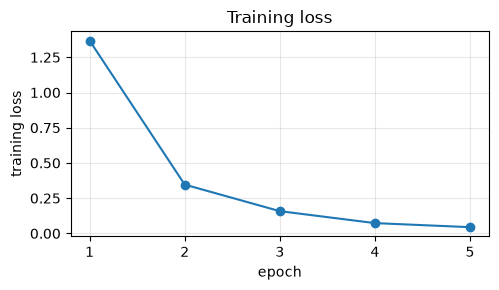

In [13]:
fig, ax = plt.subplots(figsize=(5, 3))
ax.plot(range(1, EPOCHS + 1), epoch_losses, marker="o")
ax.set(xlabel="epoch", ylabel="training loss", title="Training loss")
ax.set_xticks(range(1, EPOCHS + 1))
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(FIG_DIR / "training_loss.png", dpi=150, bbox_inches="tight")
plt.show()

## 4. Testing and F1

How the test works:

1. The 1,183 test photos, never seen in training, go through the model with `torch.no_grad()`, so nothing is learned during testing.
2. Each photo gets 12 scores; the highest one (`argmax`) is the predicted breed.
3. The predictions are compared with the true labels, breed by breed.

How the score works:

- **Accuracy**: the share of test photos given the correct breed.
- **Precision** for one breed: when the model says "Bengal", how often is it right?
- **Recall** for one breed: of all the Bengal photos, how many does it find?
- **F1** = 2 × precision × recall / (precision + recall): one number from 0 to 1 that is only high when both are high.
- **Macro F1**: the plain average of the 12 per-breed F1 scores, so a hard breed counts as much as an easy one.

The same test runs twice, before and after training. With 12 breeds, pure guessing gets about 1 photo in 12 right (0.083).

In [14]:
pred_after, _ = predict(model, test_loader)


def scores(pred):
    return [accuracy_score(y_test, pred), f1_score(y_test, pred, average="macro")]


summary = pd.DataFrame(
    {"Before training": scores(pred_before), "After training": scores(pred_after)},
    index=["Accuracy", "Macro F1"],
)
summary["Change"] = summary["After training"] - summary["Before training"]
summary.round(3)

,Before training,After training,Change
Accuracy,0.060,0.852,0.792
Macro F1,0.047,0.853,0.806


In [15]:
breeds = range(len(class_names))
f1_table = pd.DataFrame({
    "Before": f1_score(y_test, pred_before, average=None, labels=breeds, zero_division=0),
    "After": f1_score(y_test, pred_after, average=None, labels=breeds),
}, index=class_names)
f1_table["Change"] = f1_table["After"] - f1_table["Before"]
f1_table.round(3)

,Before,After,Change
Abyssinian,0.101,0.820,0.719
Bengal,0.013,0.798,0.785
Birman,0.000,0.753,0.753
Bombay,0.016,0.967,0.951
British Shorthair,0.050,0.887,0.836
Egyptian Mau,0.110,0.889,0.779
Maine Coon,0.122,0.798,0.676
Persian,0.090,0.844,0.754
Ragdoll,0.000,0.705,0.705
Russian Blue,0.019,0.913,0.894


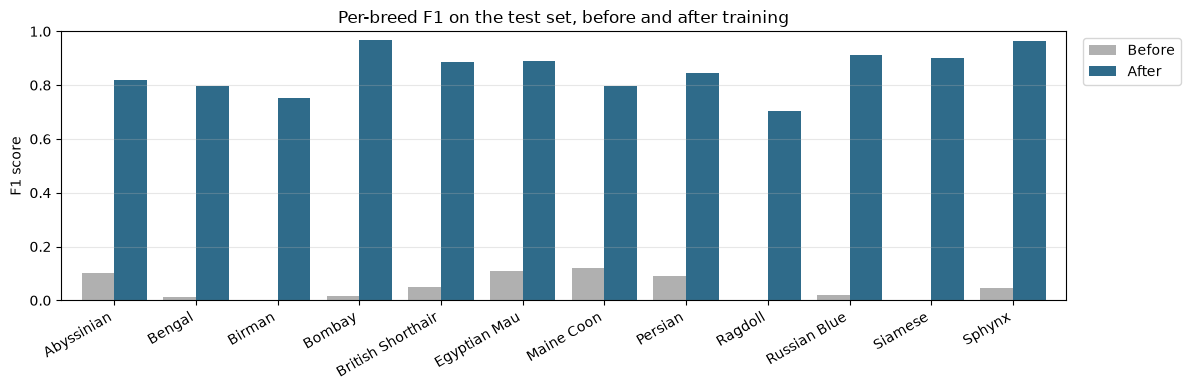

In [16]:
fig, ax = plt.subplots(figsize=(12, 4))
f1_table[["Before", "After"]].plot.bar(ax=ax, width=0.8, color=["#b0b0b0", "#2f6b8a"])
ax.set(ylabel="F1 score", ylim=(0, 1))
ax.set_title("Per-breed F1 on the test set, before and after training")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1))
ax.grid(axis="y", alpha=0.3)
plt.xticks(rotation=30, ha="right")
fig.tight_layout()
fig.savefig(FIG_DIR / "f1_before_after.png", dpi=150, bbox_inches="tight")
plt.show()

Sample predictions on 8 random test photos after training (green = correct, red = wrong). The pick uses the fixed seed, so the same 8 photos appear on every run.

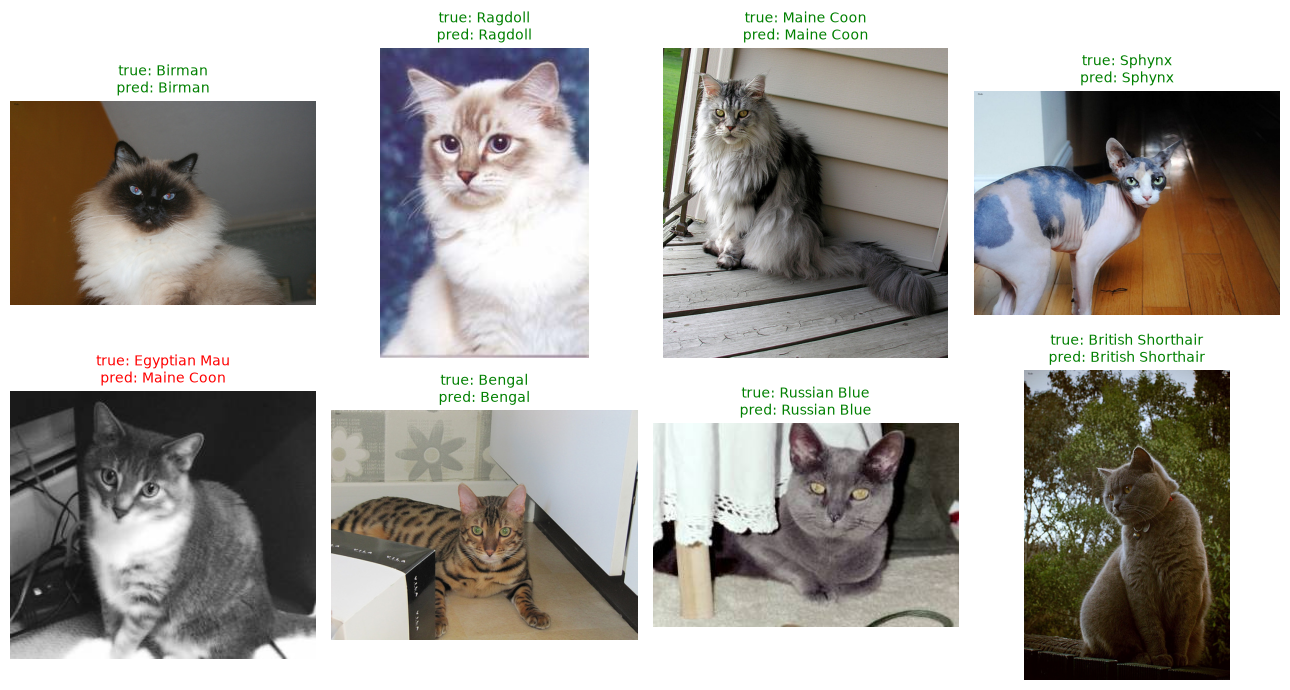

In [17]:
rng = np.random.default_rng(SEED)
fig, axes = plt.subplots(2, 4, figsize=(13, 7))
for ax, i in zip(axes.flat, rng.choice(len(test_data), 8, replace=False)):
    true, pred = class_names[y_test[i]], class_names[pred_after[i]]
    ax.imshow(test_data[int(i)]["image"])
    color = "green" if true == pred else "red"
    ax.set_title(f"true: {true}\npred: {pred}", color=color, fontsize=10)
    ax.axis("off")
fig.tight_layout()
fig.savefig(FIG_DIR / "sample_predictions.png", dpi=120, bbox_inches="tight")
plt.show()

In [18]:
summary.round(4).to_csv(RESULTS_DIR / "summary.csv")
f1_table.round(4).to_csv(RESULTS_DIR / "f1_per_breed.csv")
parts.to_csv(RESULTS_DIR / "model_parts.csv")

## 5. Summary

| | Before training | After training | Change |
|---|---|---|---|
| Accuracy | 0.060 | 0.852 | +0.792 |
| Macro F1 | 0.047 | 0.853 | +0.806 |

- **1. Data selection:** 12 cat breeds from the Oxford-IIIT Pet dataset; 1,188 training and 1,183 test photos, each labelled with its breed.
- **2. Pre-processing:** every photo converted to RGB, resized to 224 × 224 and normalised; training photos are randomly flipped.
- **3. Fine-tuning:** DeiT-Tiny, a 5.5 M-parameter Vision Transformer, chosen for its small size and ImageNet-1k pre-training. The 1,000-class ImageNet head is swapped for a new, randomly started 12-class head, and all layers are trained for 190 steps on the labelled cat photos.
- **4. Testing and F1:** macro F1 rises from 0.047 (close to random guessing) to 0.853. Every breed improves. The best breeds are Bombay and Sphynx (F1 0.97); the weakest are Ragdoll (0.70) and Birman (0.75), two long-haired breeds with similar colour-point coats (pale body, darker face, ears, paws and tail).
- **Bias:** all photos come from the web and mostly show pedigree cats, so the score is likely optimistic for everyday or mixed-breed cats, which the model must still assign to one of the 12 breeds.
- **Ethics:** the photos belong to their owners and are shared under CC BY-SA 4.0. A breed prediction is a suggestion, not proof of pedigree.